# 🎙️ TimeXer‑DINOv3: Dự đoán nhóm tuổi từ giọng nói
*Thay khối Endogenous Embedding của TimeXer bằng DINOv3 · dữ liệu theo luồng thu thập thực tế · triển khai web*

**TL;DR**
1. **Mô hình**: TimeXer (self‑attention theo thời gian + cross‑attention với biến ngoại sinh) với khối (a) *Endogenous Embedding* thay bằng **DINOv3 ViT‑S/16** chạy trên ảnh log‑Mel; CLS token của DINOv3 đóng vai trò *global token*.
2. **Dữ liệu**: xây theo luồng *thiết bị → thu thập → truyền → lưu trữ → tiền xử lý → biến đầu vào (y: log‑Mel/MFCC/F0/formant/energy; x: thời gian + ngữ cảnh ghi âm) → split theo speaker*. Seed từ Common Voice 17 (vi + en, CC0) + bản ghi private qua trang `/collect`.
3. **Hệ thống**: FastAPI + UI (ghi âm / tải file → xác suất 5 nhóm tuổi → lịch sử), model xuất ONNX, Dockerfile cho HF Spaces.

Notebook này đọc các artefact đã tạo bởi `scripts/01…08` (có thể chạy lại từng bước bằng cách bật `RUN_PIPELINE`).

In [1]:
import sys, json, os
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if (Path.cwd().name == 'notebooks') else Path.cwd()
sys.path.insert(0, str(ROOT))
RUN_PIPELINE = False   # True: chạy lại toàn bộ pipeline (tải seed, build, cache, train) — mất ~30-40 phút trên CPU

from src.common.constants import AGE_GROUPS, EXOG_COLS, COMMON_VOICE_AGE_MAP
PROC = ROOT / 'data' / 'processed'
print('ROOT =', ROOT)
print('Age groups:', AGE_GROUPS)
print('Exogenous cols:', EXOG_COLS)

ROOT = C:\TailieucuaSang\Time-series\timexer-dinov3-voice-age
Age groups: ['<18', '18-29', '30-49', '50-64', '65+']
Exogenous cols: ['hour_sin', 'hour_cos', 'dow_sin', 'dow_cos', 'duration_norm', 'snr_db_norm', 'rms_db_norm', 'source_mic', 'orig_sr_norm', 'f0_contour', 'energy_contour', 'zcr_contour', 'centroid_contour']


## 1. Luồng dữ liệu (slide 2)

```
Thiết bị vật lý ──Thu thập──▶ Truyền dữ liệu ──▶ Lưu trữ (máy chủ)        data/raw/private/<id>.wav + .json
      ▼
Tiền xử lý: khử nhiễu → cắt im lặng & chuẩn hoá 5 s → chuẩn hoá biên độ   src/data/audio_processing.py
      ▼
Biến đầu vào:  y = log‑Mel [128×251] (+MFCC, F0, formant, energy)          mel_logspec.npy / features_scalar.csv
               x = [13×251] thời gian ghi + ngữ cảnh ghi âm + F0/energy/ZCR/centroid theo khung   exog_series.npy
      ▼
Chia train/val/test theo SPEAKER ──▶ Huấn luyện ──▶ Đánh giá ──▶ Thông báo kết quả (UI)
```

Seed có nhãn: `scripts/01_seed_common_voice.py` (Common Voice 17 — mirror parquet không gate). Ánh xạ nhãn thập niên → 5 nhóm:

In [2]:
pd.Series(COMMON_VOICE_AGE_MAP).rename('age_group').to_frame().T

,teens,twenties,thirties,fourties,fifties,sixties,seventies,eighties,nineties
age_group,<18,18-29,30-49,30-49,50-64,50-64,65+,65+,65+


In [3]:
if RUN_PIPELINE:
    !python {ROOT}/scripts/01_seed_common_voice.py
    !python {ROOT}/scripts/02_ingest_private.py
    !python {ROOT}/scripts/03_build_dataset.py --save-wav
manifest = json.loads((PROC / 'dataset_manifest.json').read_text(encoding='utf-8'))
meta = pd.read_csv(PROC / 'metadata.csv')
scal = pd.read_csv(PROC / 'features_scalar.csv')
print(json.dumps({k: manifest[k] for k in ['n_clips','n_speakers','label_counts','split_counts','sources','split_strategy']}, indent=1, ensure_ascii=False))

{
 "n_clips": 8469,
 "n_speakers": 3028,
 "label_counts": {
  "<18": 1594,
  "18-29": 2409,
  "30-49": 1924,
  "50-64": 1857,
  "65+": 685
 },
 "split_counts": {
  "train": 6184,
  "test": 1255,
  "val": 1030
 },
 "sources": {
  "common_voice_17_en": 6492,
  "common_voice_17_vi": 1977
 },
 "split_strategy": "speaker-disjoint, stratified by speaker's dominant age group"
}


## 2. EDA

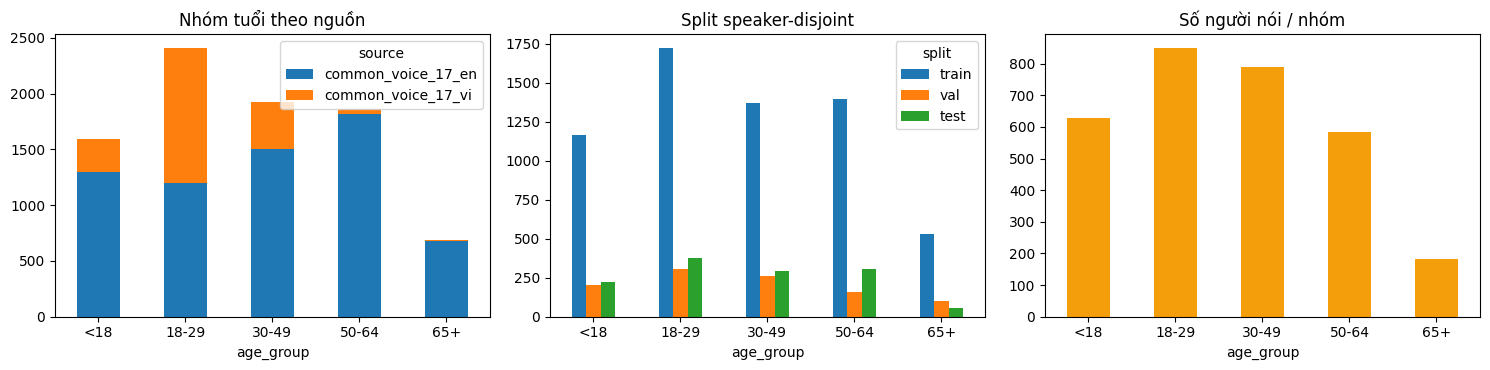

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
pd.crosstab(meta.age_group, meta.source).reindex(AGE_GROUPS).plot.bar(stacked=True, ax=ax[0], rot=0, title='Nhóm tuổi theo nguồn')
pd.crosstab(meta.age_group, meta.split).reindex(AGE_GROUPS)[['train','val','test']].plot.bar(ax=ax[1], rot=0, title='Split speaker-disjoint')
meta.groupby('age_group').speaker_id.nunique().reindex(AGE_GROUPS).plot.bar(ax=ax[2], rot=0, color='#f59e0b', title='Số người nói / nhóm')
plt.tight_layout(); plt.show()

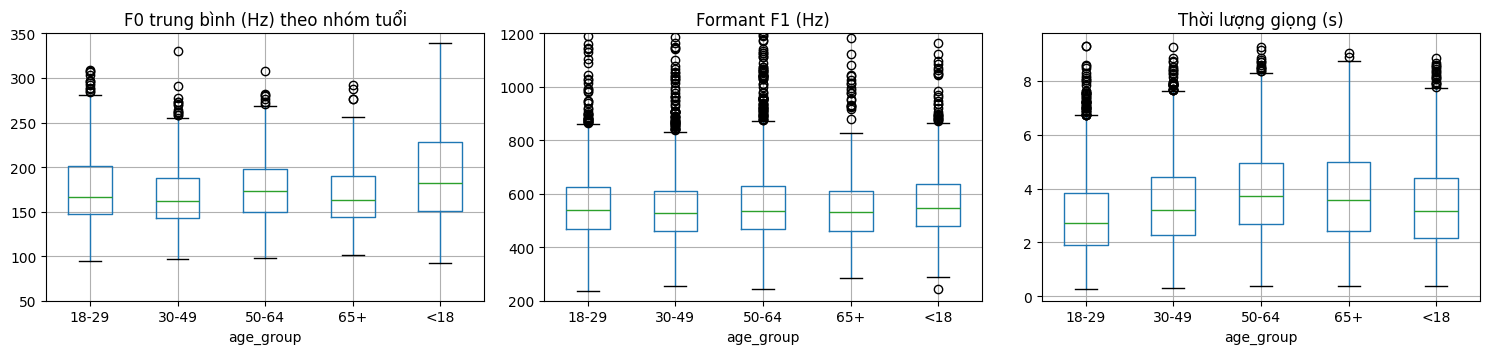

Gợi ý: F0 giảm theo tuổi ở nữ, tăng nhẹ ở nam lớn tuổi; formant thay đổi theo kích thước ống thanh — là các đặc trưng kinh điển cho dự đoán tuổi.


In [5]:
df = meta.merge(scal, on='clip_id')
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
df.boxplot(column='f0_mean', by='age_group', ax=ax[0], positions=range(5)); ax[0].set_title('F0 trung bình (Hz) theo nhóm tuổi'); ax[0].set_ylim(50, 350)
df.boxplot(column='formant_f1', by='age_group', ax=ax[1]); ax[1].set_title('Formant F1 (Hz)'); ax[1].set_ylim(200, 1200)
df.boxplot(column='speech_duration_s', by='age_group', ax=ax[2]); ax[2].set_title('Thời lượng giọng (s)')
plt.suptitle(''); plt.tight_layout(); plt.show()
print('Gợi ý: F0 giảm theo tuổi ở nữ, tăng nhẹ ở nam lớn tuổi; formant thay đổi theo kích thước ống thanh — là các đặc trưng kinh điển cho dự đoán tuổi.')

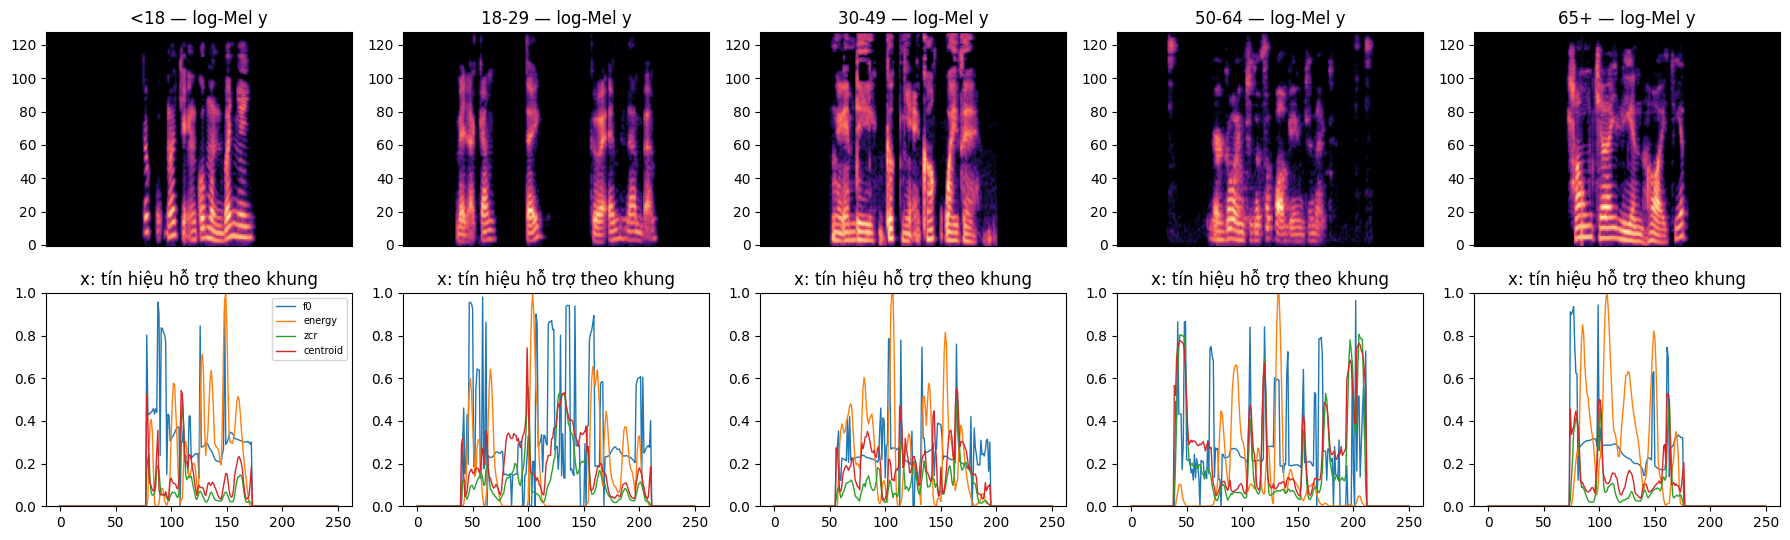

In [6]:
mel = np.load(PROC / 'mel_logspec.npy', mmap_mode='r'); exog = np.load(PROC / 'exog_series.npy', mmap_mode='r')
fig, axes = plt.subplots(2, 5, figsize=(18, 5.5))
for j, g in enumerate(AGE_GROUPS):
    i = meta.index[(meta.age_group == g) & (meta.split == 'train')][0]
    axes[0, j].imshow(np.asarray(mel[i], dtype=np.float32), origin='lower', aspect='auto', cmap='magma'); axes[0, j].set_title(f'{g} — log-Mel y'); axes[0, j].set_xticks([])
    e = np.asarray(exog[i], dtype=np.float32)
    for k, c in enumerate(['f0_contour', 'energy_contour', 'zcr_contour', 'centroid_contour']):
        axes[1, j].plot(e[EXOG_COLS.index(c)], label=c.replace('_contour', ''), lw=1)
    axes[1, j].set_title('x: tín hiệu hỗ trợ theo khung'); axes[1, j].set_ylim(0, 1)
axes[1, 0].legend(fontsize=7)
plt.tight_layout(); plt.show()

## 3. Mô hình: TimeXer với DINOv3 làm Endogenous Encoder

| Khối TimeXer | Gốc | Dự án |
|---|---|---|
| (a) Endogenous embedding | patch 1‑D → Linear + global token ngẫu nhiên | **DINOv3 ViT‑S/16** trên ảnh log‑Mel → 14 token thời gian (nối 14 dải tần) + **CLS = global token** + 1 **prosody token** (51 thống kê MFCC/F0/formant/energy → MLP) |
| (b) Exogenous embedding | `ExEmbedding` | giữ nguyên (13 biến → 13 variate token) |
| (c)(d) Self‑/Cross‑Attention | `EncoderLayer` | giữ nguyên |
| Head | FlattenHead hồi quy | `ClassificationHead` 5 lớp |

Toàn bộ thay đổi nằm trong `src/models/dinov3_encoder.py` và `src/models/timexer_dinov3.py`.

In [7]:
import inspect, torch
from src.models.dinov3_encoder import DINOv3Encoder
from src.models.timexer_dinov3 import TimeXerDINOv3
print(inspect.getsource(DINOv3Encoder.encode_backbone)); print(inspect.getsource(DINOv3Encoder.pool_tokens)); print(inspect.getsource(TimeXerDINOv3._encode))

    def encode_backbone(self, mel: torch.Tensor) -> torch.Tensor:
        """mel [B, n_mels, T] -> raw tokens [B, 1 + H*W, embed_dim]  (token 0 = CLS, sau đó lưới H×W)."""
        img = self.to_image(mel)
        feats = self._frozen_backbone(img) if self.freeze_backbone else self.backbone.forward_features(img)
        cls = feats[:, :1]
        patches = feats[:, self.n_prefix :]  # bỏ CLS + register tokens
        return torch.cat([cls, patches], dim=1)

    def pool_tokens(self, patches: torch.Tensor) -> torch.Tensor:
        """[B, H*W, D] -> token nội sinh theo token_mode."""
        B, _, D = patches.shape
        H, W = self.grid
        if self.token_mode == "grid":
            return patches
        g = patches.reshape(B, H, W, D)
        if self.token_mode == "temporal":
            return g.mean(dim=1)  # [B, W, D]
        return g.permute(0, 2, 1, 3).reshape(B, W, H * D)  # temporal_concat: [B, W, H*D]

    def _encode(self, tokens: torch.Tensor, glb: torch.Tensor, x_ex: to

In [8]:
from src.common.constants import PROSODY_COLS
model = TimeXerDINOv3(seq_len=251, n_exog=13, dino_token_mode='temporal_concat', n_prosody=len(PROSODY_COLS))
x_mel = torch.from_numpy(np.asarray(mel[:2], dtype=np.float32)); x_ex = torch.from_numpy(np.asarray(exog[:2], dtype=np.float32)).permute(0, 2, 1)
pro = scal.set_index('clip_id').loc[meta.clip_id[:2], PROSODY_COLS].to_numpy(dtype=np.float32)
x_pro = torch.from_numpy((pro - pro.mean(0)) / (pro.std(0) + 1e-6))
with torch.no_grad():
    raw = model.en_encoder.encode_backbone(x_mel)
    logits = model(x_mel, x_ex, x_pro)
print('raw DINOv3 tokens:', tuple(raw.shape), '(CLS + 14x14 patches, 384-d)')
print('logits:', tuple(logits.shape))
n_tr = sum(p.numel() for p in model.trainable_parameters()); n_all = sum(p.numel() for p in model.parameters())
print(f'trainable {n_tr/1e6:.2f}M / total {n_all/1e6:.2f}M (backbone đóng băng)')

C:\Users\ThinkPad\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


raw DINOv3 tokens: (2, 197, 384) (CLS + 14x14 patches, 384-d)
logits: (2, 5)
trainable 1.22M / total 22.81M (backbone đóng băng)


## 4. Huấn luyện

Backbone đóng băng → chạy DINOv3 **một lần** và cache token (`04_cache_dinov3_tokens.py`), sau đó phần TimeXer (≈1M tham số) huấn luyện trong vài phút trên CPU.
Mất mát: cross‑entropy có trọng số lớp ∝ (N/n_c)^0.5 + balanced sampler + label smoothing 0.05; AdamW, cosine LR, early stopping theo macro‑F1 (val).
Ablation: `configs/voice_age_baseline.yaml` — cùng kiến trúc (kể cả prosody token) nhưng khối (a) là linear patch embedding kiểu TimeXer gốc;
`*_noprosody` — bỏ prosody token; `configs/ablation_*.yaml` — cách gộp token DINOv3 (temporal mean / grid 196 token).

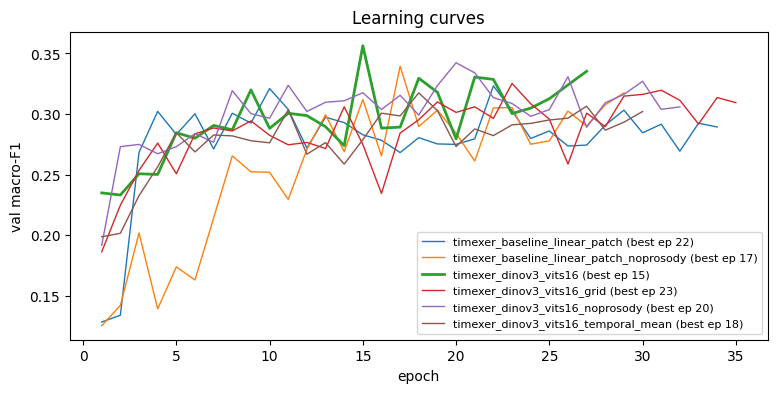

In [9]:
if RUN_PIPELINE:
    !python {ROOT}/scripts/04_cache_dinov3_tokens.py
    !python {ROOT}/scripts/05_train.py --config {ROOT}/configs/voice_age_dinov3.yaml
    !python {ROOT}/scripts/05_train.py --config {ROOT}/configs/voice_age_baseline.yaml
    !python {ROOT}/scripts/08_build_report.py
runs = {p.parent.name: json.loads(p.read_text(encoding='utf-8')) for p in (ROOT / 'checkpoints').glob('*/train_meta.json')}
plt.figure(figsize=(9, 4))
for rn, m in sorted(runs.items()):
    h = pd.DataFrame(json.loads((ROOT / 'checkpoints' / rn / 'history.json').read_text()))
    plt.plot(h.epoch, h.val_macro_f1, label=f'{rn} (best ep {m["best_epoch"]})', lw=2 if rn == 'timexer_dinov3_vits16' else 1)
plt.xlabel('epoch'); plt.ylabel('val macro-F1'); plt.legend(fontsize=8); plt.title('Learning curves'); plt.show()

## 5. Kết quả trên tập test (speaker‑disjoint)

,model,type,accuracy,balanced_accuracy,macro_f1,ordinal_mae,within_one_group_acc,params,best_epoch
0,LogReg (MFCC/F0/formant stats),classical,34.9%,32.1%,0.313,1.050,72.9%,-,nan
1,HistGradientBoosting (scalar feats),classical,40.6%,33.2%,0.328,0.910,76.6%,-,nan
2,TimeXer gốc + prosody token,timexer_baseline,36.3%,32.7%,0.321,1.073,69.8%,0.75M,22.000000
3,TimeXer gốc (linear patch embedding),timexer_baseline,30.0%,26.9%,0.251,1.073,73.3%,0.73M,17.000000
4,"TimeXer + DINOv3 ViT-S/16, temporal_concat + prosody token (đề xuất)",timexer_dinov3,39.0%,33.6%,0.335,0.944,75.5%,1.22M,15.000000
5,"TimeXer + DINOv3, token grid 196 (ablation, không prosody)",timexer_dinov3,30.5%,34.8%,0.282,1.112,71.3%,0.56M,23.000000
6,"TimeXer + DINOv3 ViT-S/16, temporal_concat (không prosody)",timexer_dinov3,35.5%,33.3%,0.307,1.039,71.8%,1.20M,20.000000
7,"TimeXer + DINOv3, token temporal mean (ablation, không prosody)",timexer_dinov3,30.9%,35.6%,0.293,1.131,70.0%,0.56M,18.000000


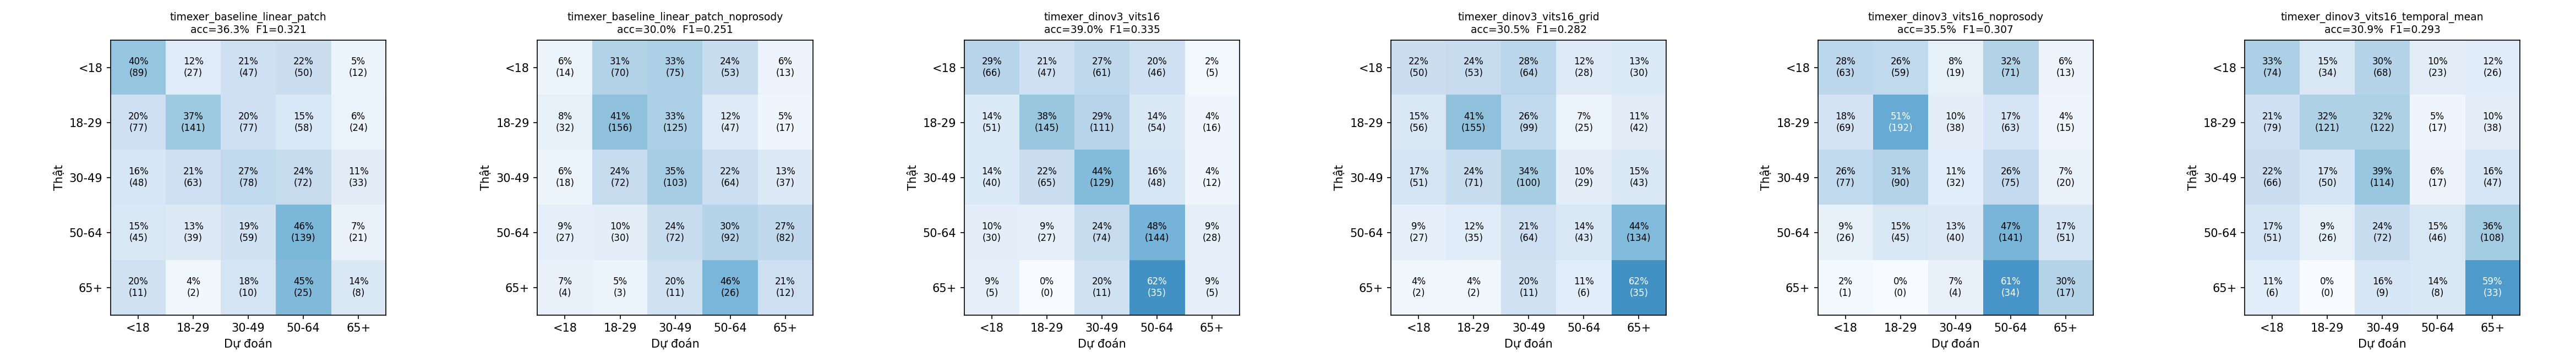

In [10]:
cmp = pd.read_json(ROOT / 'reports' / 'model_comparison.json')
display(cmp.style.format({'accuracy': '{:.1%}', 'balanced_accuracy': '{:.1%}', 'macro_f1': '{:.3f}', 'ordinal_mae': '{:.3f}', 'within_one_group_acc': '{:.1%}'}).highlight_max(subset=['macro_f1', 'accuracy'], color='#dbeafe'))
from IPython.display import Image, display as d
d(Image(filename=str(ROOT / 'reports' / 'figures' / 'fig_confusion.png')))

In [11]:
best = runs.get('timexer_dinov3_vits16')
if best:
    tm = best['test_metrics']
    print(pd.Series(tm['per_class_f1']).rename('F1 theo nhóm').to_frame().T)
    pred = pd.read_csv(ROOT / 'checkpoints' / 'timexer_dinov3_vits16' / 'test_predictions.csv')
    print('\nAccuracy theo ngôn ngữ (test):'); print(pred.assign(ok=pred.age_group == pred.pred_group).groupby('locale').ok.agg(['mean', 'size']).round(3))

                   <18     18-29     30-49     50-64       65+
F1 theo nhóm  0.316547  0.438729  0.379412  0.457143  0.081967

Accuracy theo ngôn ngữ (test):
         mean  size
locale             
en      0.350   894
vi      0.488   361


## 6. Xuất mô hình & triển khai (slide 3)

* `python scripts/07_export_model.py` → `app/model/timexer_dinov3.onnx` (toàn pipeline mel + exog + prosody → logits, đã kiểm tra sai lệch với PyTorch), `timexer_dinov3_head.pt`, `model_card.json` (kèm mean/std chuẩn hoá prosody).
* `uvicorn app.backend.main:app --port 7860` → UI *TimeXer AI* (ghi âm / tải file → kết quả 5 nhóm + độ tin cậy → lịch sử) và trang `/collect` thu thập dữ liệu private.
* `app/Dockerfile` → Hugging Face Spaces (Docker) / Render / Fly.io — xem `app/README_DEPLOY.md`.

In [12]:
card_path = ROOT / 'app' / 'model' / 'model_card.json'
if card_path.exists():
    card = json.loads(card_path.read_text(encoding='utf-8'))
    print(json.dumps({k: card[k] for k in ['run_name', 'architecture', 'dino_model', 'test_accuracy', 'test_macro_f1', 'test_within_one', 'onnx', 'exported_at']}, indent=1, ensure_ascii=False))

{
 "run_name": "timexer_dinov3_vits16",
 "architecture": "TimeXer (self-attn + exog cross-attn) with DINOv3 ViT-S/16 endogenous encoder",
 "dino_model": "vit_small_patch16_dinov3.lvd1689m",
 "test_accuracy": 0.3896414342629482,
 "test_macro_f1": 0.33475955914759814,
 "test_within_one": 0.7553784860557768,
 "onnx": true,
 "exported_at": "2026-10-18T20:34:05"
}


cven_common_voice_en_100460.wav -> 30 – 49 tuổi (44%) | backend: onnxruntime | 1712 ms


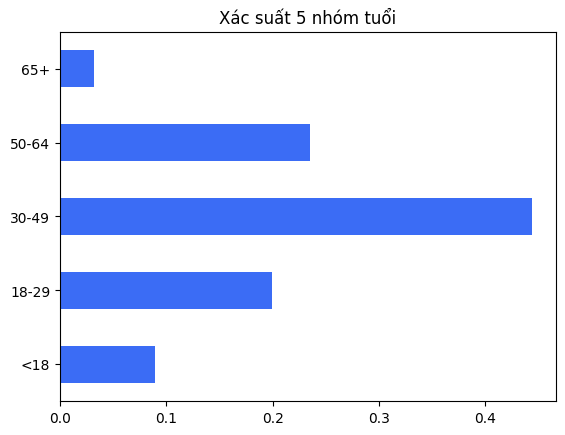

In [13]:
# Suy luận end-to-end trên một file âm thanh bất kỳ (giống backend)
from app.backend.inference import VoiceAgePredictor
pred = VoiceAgePredictor()
sample = sorted((PROC / 'audio_16k').glob('*.wav'))[0]
res = pred.predict(str(sample), source_mic=False)
print(sample.name, '->', res['pred_label_vi'], f"({res['confidence']:.0%})", '| backend:', res['backend'], '|', res['latency_ms'], 'ms')
pd.Series(res['probs']).plot.barh(color='#3b6cf5', title='Xác suất 5 nhóm tuổi'); plt.show()

## 7. Kết luận & hướng phát triển

* Đã thay thành công khối Endogenous Embedding của TimeXer bằng DINOv3 trong khi giữ nguyên phần còn lại (ExEmbedding, Self‑/Cross‑Attention), tận dụng biểu diễn thời‑tần tiền huấn luyện và CLS token làm global token.
* Pipeline dữ liệu bám đúng luồng thiết kế, có công cụ thu thập private (`/collect`) và đóng gói Kaggle; split theo speaker nên kết quả phản ánh khả năng tổng quát hoá sang người nói mới.
* Hạn chế: dữ liệu nhỏ, nhãn thập niên thô (ánh xạ xấp xỉ `teens→<18`, `sixties→50‑64`), backbone đóng băng do huấn luyện trên CPU.
* Hướng tiếp: mở băng các block cuối của DINOv3 (GPU), ảnh phổ độ phân giải thời gian cao hơn (224×448 → 28 token), thêm dữ liệu private tiếng Việt qua `/collect`, hồi quy tuổi liên tục + ordinal loss, hiệu chuẩn xác suất.